In [4]:
import cv2
import os
import glob
from datetime import timedelta
import torch
from torch.utils.data import Dataset, DataLoader
from torchvision import transforms
import torch.nn as nn
import torch.optim as optim

In [ ]:
# Read the video files from the "raw_video" folder
video_folder = "raw_video"
video_files = glob.glob(os.path.join(video_folder, "*.mp4"))
output_folder = "dataset_frames"

for video_path in video_files:
    cap = cv2.VideoCapture(video_path)
    
    if not cap.isOpened():
        print(f"Error opening {video_path}")
        continue
        
    # Read the video properties
    fps = cap.get(cv2.CAP_PROP_FPS)
    width = int(cap.get(cv2.CAP_PROP_FRAME_WIDTH))
    height = int(cap.get(cv2.CAP_PROP_FRAME_HEIGHT))
    total_frames = int(cap.get(cv2.CAP_PROP_FRAME_COUNT))
    
    # Calculate duration
    duration_seconds = total_frames / fps if fps > 0 else 0
    duration_formatted = str(timedelta(seconds=int(duration_seconds)))
    
    print(f"File: {os.path.basename(video_path)}")
    print(f" - Resolution: {width} x {height}")
    print(f" - FPS:        {fps:.2f}")
    print(f" - Frames:     {total_frames}")
    print(f" - Duration:   {duration_formatted} ({duration_seconds:.2f} seconds)")
    print("-" * 40)
    
    cap.release()

File: WIN_20261014_15_25_03_Pro.mp4
 - Resolution: 1920 x 1080
 - FPS:        29.93
 - Frames:     4008
 - Duration:   0:02:13 (133.90 seconds)
----------------------------------------
File: WIN_20261014_15_28_26_Pro.mp4
 - Resolution: 1920 x 1080
 - FPS:        29.96
 - Frames:     3902
 - Duration:   0:02:10 (130.22 seconds)
----------------------------------------
File: WIN_20261014_15_32_49_Pro.mp4
 - Resolution: 1920 x 1080
 - FPS:        29.86
 - Frames:     3596
 - Duration:   0:02:00 (120.43 seconds)
----------------------------------------
File: WIN_20261014_15_35_23_Pro.mp4
 - Resolution: 1920 x 1080
 - FPS:        29.96
 - Frames:     4483
 - Duration:   0:02:29 (149.63 seconds)
----------------------------------------


In [4]:
frame_interval = 15  # Extract every 15 frames 

# Create the output folder if it doesn't exist
os.makedirs(output_folder, exist_ok=True)

total_saved = 0
total_skipped = 0

for video_path in video_files:
    cap = cv2.VideoCapture(video_path)
    
    if not cap.isOpened():
        print(f"Error opening {video_path}")
        continue
        
    print(f"Processing '{os.path.basename(video_path)}'...")
    
    frame_count = 0
    
    while True:
        ret, frame = cap.read()
        
        if not ret:
            break 
            
        # Extract on the 15-frame interval
        if frame_count % frame_interval == 0:
            filename = os.path.join(output_folder, f"frame_{(total_saved + total_skipped):04d}.jpg")
            
            # Skip if the file already exists
            if os.path.exists(filename):
                total_skipped += 1
            else:
                cv2.imwrite(filename, frame)
                total_saved += 1
            
        frame_count += 1
        
    cap.release()

print(f"Extraction complete!")
print(f"Saved new: {total_saved}")
print(f"Skipped existing: {total_skipped}")

Processing 'WIN_20261014_15_25_03_Pro.mp4'...
Processing 'WIN_20261014_15_28_26_Pro.mp4'...
Processing 'WIN_20261014_15_32_49_Pro.mp4'...
Processing 'WIN_20261014_15_35_23_Pro.mp4'...
Extraction complete!
Saved new: 0
Skipped existing: 1068


In [ ]:
# Create a custom Dataset class for YOLO
class RoomYOLODataset(Dataset):
    def __init__(self, img_dir, label_dir, transform=None):
        self.img_dir = img_dir
        self.label_dir = label_dir
        self.transform = transform
        self.cache = {}
        
        # Get a list of all images in the folder
        self.imgs = [f for f in os.listdir(img_dir) if f.endswith('.jpg')]

    def __len__(self):
        return len(self.imgs)

    def __getitem__(self, idx):
        # Check if the item is already in cache
        if idx in self.cache:
            return self.cache[idx]
        
        # Load the Image
        img_name = self.imgs[idx]
        img_path = os.path.join(self.img_dir, img_name)
        
        # OpenCV loads images in BGR format, but PyTorch expects RGB
        image = cv2.imread(img_path)
        image = cv2.cvtColor(image, cv2.COLOR_BGR2RGB)
        
        # Find the matching label file
        label_name = img_name.replace('.jpg', '.txt')
        label_path = os.path.join(self.label_dir, label_name)
        
        # Parse the Label (Handling Negative Samples)
        # Target format: [is_person, x_center, y_center, width, height]
        if os.path.exists(label_path) and os.path.getsize(label_path) > 0:
            with open(label_path, 'r') as f:
                # YOLO format: class_id x_center y_center width height
                data = f.readline().strip().split()
                is_person = 1.0
                target = [is_person, float(data[1]), float(data[2]), float(data[3]), float(data[4])]
        else:
            # is_person = 0.0
            target = [0.0, 0.0, 0.0, 0.0, 0.0]
            
        target_tensor = torch.tensor(target, dtype=torch.float32)
        
        # Apply transformations
        if self.transform:
            image = self.transform(image)

        # Save the final tensors to the cache before returning them
        self.cache[idx] = (image, target_tensor)

        return image, target_tensor

# Define the Simple YOLO Model
class SimpleYOLO(nn.Module):
    def __init__(self):
        super(SimpleYOLO, self).__init__()
        self.conv1 = nn.Conv2d(3, 32, 3, 1, padding=1)
        self.conv2 = nn.Conv2d(32, 64, 3, 1, padding=1)
        self.conv3 = nn.Conv2d(64, 128, 3, 1, padding=1)
        self.pool = nn.MaxPool2d(2, 2)
        self.batch_norm1 = nn.BatchNorm2d(32)
        self.batch_norm2 = nn.BatchNorm2d(64)
        self.batch_norm3 = nn.BatchNorm2d(128)
        self.fc1 = nn.Linear(128 * 32 * 32, 512)
        self.fc2 = nn.Linear(512, 256)
        
        # Apply Linear layers for Confidence and Bounding Box Predictions
        self.head_conf = nn.Linear(256, 1)
        self.head_box = nn.Linear(256, 4)
        
        self.dropout = nn.Dropout(0.5)
        self.leaky_relu = nn.LeakyReLU(0.1)

    def forward(self, x):
        x = self.pool(self.leaky_relu(self.batch_norm1(self.conv1(x))))
        x = self.pool(self.leaky_relu(self.batch_norm2(self.conv2(x))))
        x = self.pool(self.leaky_relu(self.batch_norm3(self.conv3(x))))
        x = x.view(x.size(0), -1)
        x = self.leaky_relu(self.fc1(x))
        x = self.leaky_relu(self.fc2(x))
        
        conf_logits = self.head_conf(x)       
        box_coords = torch.sigmoid(self.head_box(x))
        return torch.cat((conf_logits, box_coords), dim=1)

# Define the YOLO Loss Function
class YOLOLoss(nn.Module):
    def __init__(self):
        super(YOLOLoss, self).__init__()
        self.mse = nn.MSELoss(reduction='none')
        
        # Force the model to care 5x more about the "Person" class
        self.bce = nn.BCEWithLogitsLoss(reduction='mean', pos_weight=torch.tensor([5.0]))

    def forward(self, predictions, targets):
        pred_conf = predictions[:, 0]
        target_conf = targets[:, 0]
        pred_boxes = predictions[:, 1:5]
        target_boxes = targets[:, 1:5]

        # Confidence Loss
        loss_conf = self.bce(pred_conf, target_conf)

        # Box Loss
        mask = target_conf.unsqueeze(1)
        raw_box_error = self.mse(pred_boxes, target_boxes) * mask
        
        num_active_boxes = target_conf.sum()
        
        if num_active_boxes > 0:
            loss_box = raw_box_error.sum() / num_active_boxes
        else:
            loss_box = torch.tensor(0.0, device=predictions.device)

        # Combine 
        total_loss = loss_conf + (loss_box * 5.0)
        
        return total_loss

In [ ]:
# Setup the training components
device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')

my_transforms = transforms.Compose([
    transforms.ToTensor(),
    transforms.Resize((256, 256))
])

dataset = RoomYOLODataset(img_dir='dataset_frames', label_dir='dataset_labels', transform=my_transforms)
dataloader = DataLoader(
    dataset, 
    batch_size=16, 
    shuffle=True,
    num_workers=0,        
    pin_memory=True
    )

model = SimpleYOLO().to(device)
criterion = YOLOLoss().to(device)
optimizer = optim.Adam(model.parameters(), lr=0.0001)

# Training Loop
epochs = 200

for epoch in range(epochs):
    model.train()
    total_batch_loss = 0
    
    for images, targets in dataloader:
        images = images.to(device)
        targets = targets.to(device)

        optimizer.zero_grad()
        predictions = model(images)
        loss = criterion(predictions, targets)

        loss.backward()
        optimizer.step()
        
        total_batch_loss += loss.item()
        
    print(f"Epoch [{epoch+1}/{epochs}] - Loss: {total_batch_loss / len(dataloader):.4f}")

Epoch [1/200] - Loss: 3.4040
Epoch [2/200] - Loss: 2.6827
Epoch [3/200] - Loss: 2.6233
Epoch [4/200] - Loss: 2.5457
Epoch [5/200] - Loss: 2.4122
Epoch [6/200] - Loss: 2.4635
Epoch [7/200] - Loss: 2.5078
Epoch [8/200] - Loss: 2.3992
Epoch [9/200] - Loss: 2.2647
Epoch [10/200] - Loss: 1.6894
Epoch [11/200] - Loss: 0.7006
Epoch [12/200] - Loss: 0.3559
Epoch [13/200] - Loss: 0.2235
Epoch [14/200] - Loss: 0.2060
Epoch [15/200] - Loss: 0.1988
Epoch [16/200] - Loss: 0.2109
Epoch [17/200] - Loss: 0.2428
Epoch [18/200] - Loss: 0.1895
Epoch [19/200] - Loss: 0.1730
Epoch [20/200] - Loss: 0.1497
Epoch [21/200] - Loss: 0.1384
Epoch [22/200] - Loss: 0.1186
Epoch [23/200] - Loss: 0.1595
Epoch [24/200] - Loss: 0.2226
Epoch [25/200] - Loss: 0.1715
Epoch [26/200] - Loss: 0.1517
Epoch [27/200] - Loss: 0.1301
Epoch [28/200] - Loss: 0.1902
Epoch [29/200] - Loss: 0.1604
Epoch [30/200] - Loss: 0.1701
Epoch [31/200] - Loss: 0.1276
Epoch [32/200] - Loss: 0.1058
Epoch [33/200] - Loss: 0.1301
Epoch [34/200] - Lo

Room is empty. (Confidence: 0.00%)


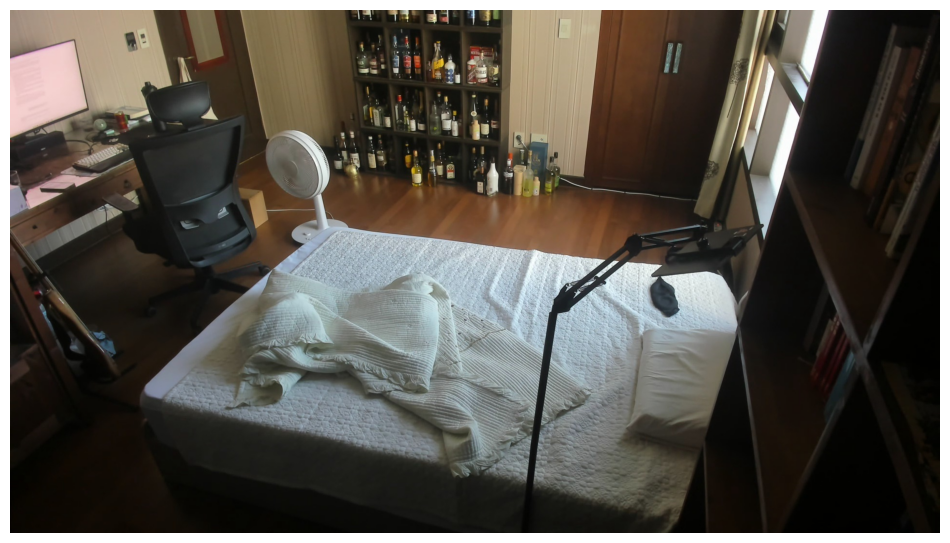

In [67]:
import cv2
import torch
import matplotlib.pyplot as plt
import random

# 1. Lock the model for testing
# This turns off Dropout and locks BatchNorm so the model doesn't try to learn from the test image!
model.eval() 

# Pick an image from your dataset (or a brand new frame)
random_frame_number = random.randint(0, len(dataset) - 1)
test_image_path = f'dataset_frames/frame_{random_frame_number:04d}.jpg'

# 2. Pre-process the image
# OpenCV loads as BGR, we need RGB
original_image = cv2.imread(test_image_path)
original_image = cv2.cvtColor(original_image, cv2.COLOR_BGR2RGB)

# Save the original dimensions (e.g., 1080 height, 1920 width)
h_orig, w_orig, _ = original_image.shape

# Resize to the 256x256 that our model expects and convert to Tensor
input_tensor = my_transforms(original_image).unsqueeze(0).to(device) # unsqueeze adds a fake batch dimension of 1

# 3. The Forward Pass (Inference)
# torch.no_grad() tells the RTX 5070 "Don't track memory for backpropagation, just calculate the answer fast"
with torch.no_grad():
    prediction = model(input_tensor)

# Extract the 5 numbers and move them back to the CPU
prediction = prediction.cpu()[0] 

# Apply Sigmoid to the confidence score to turn it into a clean 0.0 to 1.0 probability
confidence = torch.sigmoid(prediction[0]).item()

# 4. Post-processing: The Aspect Ratio Magic
if confidence > 0.5:  # If the model is more than 50% sure a person is there
    print(f"Person detected! Confidence: {confidence*100:.2f}%")
    
    # YOLO outputs normalized percentages (0.0 to 1.0). 
    # To unsquish the box, we just multiply the percentages by the native 1920x1080 resolution!
    x_center_pct, y_center_pct, w_pct, h_pct = prediction[1:5].numpy()
    
    x_center = int(x_center_pct * w_orig)
    y_center = int(y_center_pct * h_orig)
    w = int(w_pct * w_orig)
    h = int(h_pct * h_orig)
    
    # OpenCV requires top-left and bottom-right corners to draw a rectangle
    x1 = int(x_center - (w / 2))
    y1 = int(y_center - (h / 2))
    x2 = int(x_center + (w / 2))
    y2 = int(y_center + (h / 2))
    
    # Draw a green box (RGB: 0, 255, 0) with a thickness of 5
    cv2.rectangle(original_image, (x1, y1), (x2, y2), (0, 255, 0), 5)
    
else:
    print(f"Room is empty. (Confidence: {confidence*100:.2f}%)")

# 5. Display the result in the notebook
plt.figure(figsize=(12, 8))
plt.imshow(original_image)
plt.axis('off')
plt.show()

In [68]:
import os
import shutil
import random

def move_test_split(frames_dir='dataset_frames', 
                    labels_dir='dataset_labels', 
                    test_frames_dir='test_frames', 
                    test_labels_dir='test_labels', 
                    ratio=0.15, 
                    seed=42):
    
    # Set seed for reproducible random selection
    random.seed(seed)
    
    # Create target directories
    os.makedirs(test_frames_dir, exist_ok=True)
    os.makedirs(test_labels_dir, exist_ok=True)
    
    # Get list of valid images
    valid_extensions = ('.jpg', '.jpeg', '.png')
    all_images = [f for f in os.listdir(frames_dir) if f.lower().endswith(valid_extensions)]
    
    if not all_images:
        print(f"No images found in '{frames_dir}'. Please check the directory path.")
        return

    # Calculate 15% count
    num_to_move = int(len(all_images) * ratio)
    selected_images = random.sample(all_images, num_to_move)
    
    moved_images_count = 0
    moved_labels_count = 0
    
    for img_name in selected_images:
        # Determine image paths
        src_img = os.path.join(frames_dir, img_name)
        dst_img = os.path.join(test_frames_dir, img_name)
        
        # Determine matching label file name
        base_name = os.path.splitext(img_name)[0]
        label_name = f"{base_name}.txt"
        
        # Explicit safety check: NEVER touch classes.txt
        if label_name.lower() == 'classes.txt':
            continue
            
        src_label = os.path.join(labels_dir, label_name)
        dst_label = os.path.join(test_labels_dir, label_name)
        
        # Move the image
        shutil.move(src_img, dst_img)
        moved_images_count += 1
        
        # Move the matching label file if it exists
        if os.path.exists(src_label):
            shutil.move(src_label, dst_label)
            moved_labels_count += 1

    print("--- DATASET SPLIT COMPLETE ---")
    print(f"Total dataset size: {len(all_images)} frames")
    print(f"Moved {moved_images_count} images to '{test_frames_dir}' ({ratio * 100:.0f}%)")
    print(f"Moved {moved_labels_count} label files to '{test_labels_dir}'")
    print(f"Verified: 'classes.txt' remains untouched in '{labels_dir}'")

if __name__ == "__main__":
    move_test_split()

--- DATASET SPLIT COMPLETE ---
Total dataset size: 1068 frames
Moved 160 images to 'test_frames' (15%)
Moved 123 label files to 'test_labels'
Verified: 'classes.txt' remains untouched in 'dataset_labels'


In [ ]:
import sys
import os
import torch
from torch.utils.data import DataLoader
from torchvision import transforms

sys.path.append(os.path.abspath(os.path.join(os.path.dirname(__file__), '..')))

from src.dataset import RoomYOLODataset
from src.model import SimpleYOLO

def calculate_iou(boxA, boxB):
    xA1 = boxA[0] - (boxA[2] / 2)
    yA1 = boxA[1] - (boxA[3] / 2)
    xA2 = boxA[0] + (boxA[2] / 2)
    yA2 = boxA[1] + (boxA[3] / 2)
    
    xB1 = boxB[0] - (boxB[2] / 2)
    yB1 = boxB[1] - (boxB[3] / 2)
    xB2 = boxB[0] + (boxB[2] / 2)
    yB2 = boxB[1] + (boxB[3] / 2)
    
    inter_x1 = max(xA1, xB1)
    inter_y1 = max(yA1, yB1)
    inter_x2 = min(xA2, xB2)
    inter_y2 = min(yA2, yB2)
    
    inter_w = max(0.0, inter_x2 - inter_x1)
    inter_h = max(0.0, inter_y2 - inter_y1)
    inter_area = inter_w * inter_h
    
    boxA_area = boxA[2] * boxA[3]
    boxB_area = boxB[2] * boxB[3]
    
    union_area = boxA_area + boxB_area - inter_area
    if union_area == 0: return 0.0
    return inter_area / union_area

def main():
    device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
    my_transforms = transforms.Compose([transforms.ToTensor(), transforms.Resize((256, 256))])
    
    test_dataset = RoomYOLODataset(img_dir='test_frames', label_dir='test_labels', transform=my_transforms)
    test_loader = DataLoader(test_dataset, batch_size=1, shuffle=False)

    model = SimpleYOLO().to(device)
    weights_path = os.path.join(os.path.dirname(__file__), '..', 'room_yolo_weights.pth')
    model.load_state_dict(torch.load(weights_path, map_location=device))
    model.eval()

    correct_classifications = 0
    total_iou = 0.0
    true_positives = 0

    with torch.no_grad():
        for images, targets in test_loader:
            images = images.to(device)
            targets = targets.cpu()[0]
            
            predictions = model(images).cpu()[0]
            pred_conf = torch.sigmoid(predictions[0]).item()
            
            target_conf = targets[0].item()
            pred_class = 1.0 if pred_conf > 0.5 else 0.0
            
            if pred_class == target_conf:
                correct_classifications += 1
                
            if pred_class == 1.0 and target_conf == 1.0:
                pred_box = predictions[1:5].numpy()
                target_box = targets[1:5].numpy()
                iou = calculate_iou(pred_box, target_box)
                total_iou += iou
                true_positives += 1

    total_images = len(test_dataset)
    class_acc = (correct_classifications / total_images) * 100
    avg_iou = (total_iou / true_positives) if true_positives > 0 else 0.0

    print(f"--- EVALUATION REPORT ---")
    print(f"Accuracy: {class_acc:.2f}% | Avg IoU: {avg_iou:.4f}")

if __name__ == "__main__":
    main()

--- PRODUCTION EVALUATION REPORT ---
Total Test Frames Evaluated: 160
Classification Accuracy: 100.00%
False Positives (Ghost Detections): 0
False Negatives (Missed Persons): 0
Average Bounding Box IoU: 0.9088
